# Single-RF tutorial: two groups within each image

Illustrate preprocessing and pre-RF GMM on the same example image as the implementation tutorial. For supervised training, use **eight images that each contain both parent group 1 and parent group 3**. Map archived raw labels **11 and 12 → group 1**, **31 and 32 → group 3**. Preserve raw labels in saved tables. This is a single binary RF, with no hierarchical routing or second-stage GMM.

Four fixed folds train on six images and predict the other two; every image is held out once. Each fold's same RF is scored both directly and with majority voting inside pre-RF GMM groups. Scores use identical eligible superpixels. The separate all-eight final model is never used for scoring.

Images were visually inspected for a teaching example, not randomly sampled for an external benchmark. Reference annotations assign whole GMM groups, so voting can improve agreement by enforcing that same structure; the scores are not independent pixel-level accuracy. Use **Python (crystal_seg)** from `training/` or the project root. All plotting code stays inline. Images retain their original resolution.

## 1. Paths and configuration

In [1]:
from pathlib import Path
import sys, json, ast, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): WORK_DIR /= "training"
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from training/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))
from crystal_pipeline import _natural_key
from crystal_preprocessing import preprocess_image
from crystal_features import calculate_image_features, FEATURE_NAMES, FEATURE_CALCULATION
from crystal_gmm import fit_image_gmm

# Match the implementation tutorial's current illustrative image.
IMAGE_PATH = PROJECT_ROOT / "data/mag500/old/pl09/20260806_140719.jpg"
TRAINING_DIR = PROJECT_ROOT / "data/mag500/training"
ARCHIVE_PATH = WORK_DIR / "archive/superpixel_RF_GMM_training.ipynb"
REFERENCE_PATH = WORK_DIR / "data/models/color_reference.pkl"
OUTPUT_DIR = WORK_DIR / "output/tutorial_mixed_groups_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {"crop": {"top": 60, "bottom": 100, "left": 60, "right": 100}, "n_segments": 300, "compactness": 10.0}
CLASS_IDS = [1, 3]
LABEL_TO_CLASS = {11: 1, 12: 1, 31: 3, 32: 3}  # Preserve raw annotations; train one binary parent-group RF.
GMM_PROBABILITY_CUT = .70
reference = np.asarray(joblib.load(REFERENCE_PATH)["reference_mean"], dtype=np.float64)
print(f"Example image: {IMAGE_PATH}\nTraining folder: {TRAINING_DIR}\nOutputs: {OUTPUT_DIR}")
from sklearn.ensemble import RandomForestClassifier
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=2, class_weight="balanced", random_state=0, n_jobs=1)
CV_DIR = OUTPUT_DIR / "cross_validation"


Example image: /home/kmanabe2403/dune/data/mag500/old/pl09/20260806_140719.jpg
Training folder: /home/kmanabe2403/dune/data/mag500/training
Outputs: /home/kmanabe2403/dune/training/output/tutorial_mixed_groups_001


## 2. Crop the example image
Black frames show the image edges; the red rectangle marks the retained region. No resizing is applied.

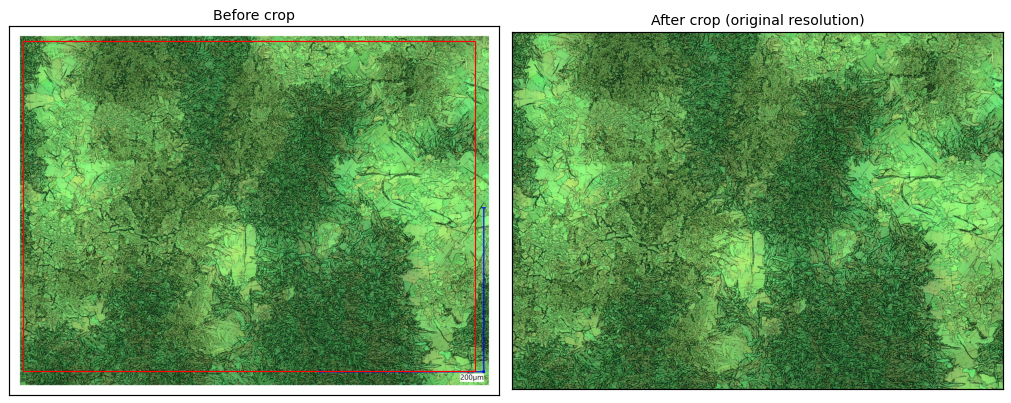

In [2]:
from skimage import io
from matplotlib.patches import Rectangle

original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = CONFIG["crop"]
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"]-.5, crop["top"]-.5), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title("Before crop")
axes[1].imshow(image)
axes[1].set_title("After crop (original resolution)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values(): spine.set(color="black", linewidth=1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=120)
plt.show()
plt.close(fig)
del original

## 3. Superpixels and the same 18 archived-training features
The helper processes one image and saves intermediate arrays before returning. Fixed-reference Lab correction and the feature calculation match the current implementation modules (`archived_training_v1`). Thin red lines show SLIC boundaries. Do not resize images or change the preprocessing/reference when reusing archived cluster IDs.

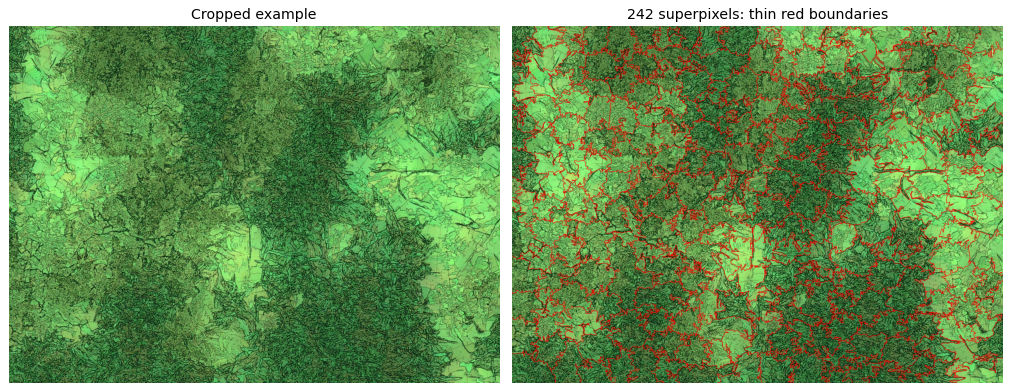

In [3]:
def prepare_image(path, directory):
    preprocess_image(path, directory, CONFIG)
    with np.load(directory / "lab_means.npz") as saved:
        labels, means = saved["labels"], saved["lab_means"]
    correction = reference - means.mean(axis=0)
    corrected = directory / "corrected_lab.npz"
    np.savez(corrected, labels=labels, lab_means=means + correction, correction=correction)
    labels, features = calculate_image_features(directory, corrected)
    feature_path = directory / "features.npz"
    np.savez(feature_path, labels=labels, features=features, feature_names=FEATURE_NAMES, feature_calculation=FEATURE_CALCULATION)
    return feature_path

from skimage.segmentation import mark_boundaries
EXAMPLE_DIR = OUTPUT_DIR / "example"
example_features = prepare_image(IMAGE_PATH, EXAMPLE_DIR)
segments = np.load(EXAMPLE_DIR / "segments.npy")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Cropped example")
axes[1].imshow(np.clip(mark_boundaries(image, segments, color=(1, 0, 0), mode="inner"), 0, 1))
axes[1].set_title(f"{len(np.unique(segments))} superpixels: thin red boundaries")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_superpixels.png", dpi=120)
plt.show()
plt.close(fig)

## 4. Pre-RF GMM: original image, area fractions and separated clusters
The layout matches the implementation tutorial: original image and pixel-area fractions on top; original-color superpixels from each GMM component on white backgrounds below. No EM-iteration or PCA-distribution plot is displayed. GMM still uses two PCs internally to match archived training. These unsupervised component IDs are not parent-group RF classes 1/3. The example image is separate from the supervised dataset.

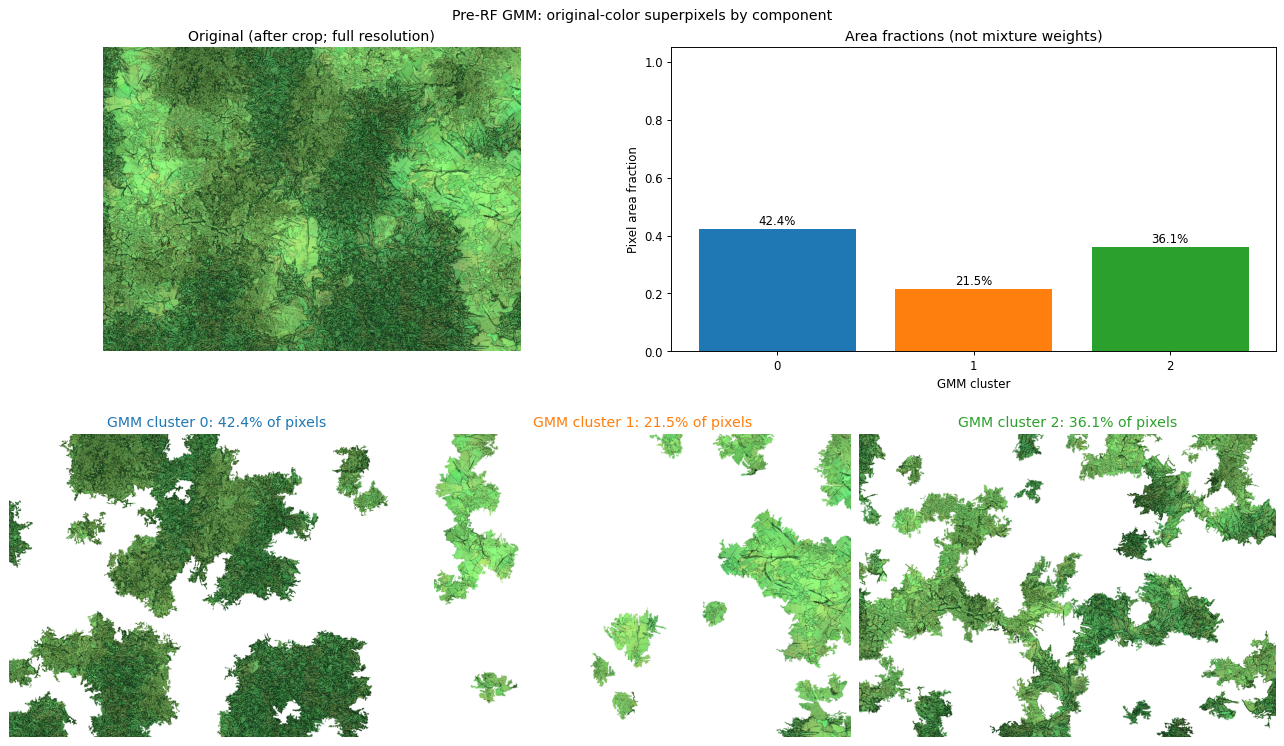

In [4]:
example_gmm = fit_image_gmm(example_features, n_components=3, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
with np.load(example_features) as saved: example_labels = saved["labels"]
cluster_labels = np.full(len(example_labels), -1, dtype=int)
cluster_labels[example_gmm["valid_indices"]] = example_gmm["cluster_labels"]
cluster_map = cluster_labels[np.searchsorted(example_labels, segments)]
colors = plt.cm.tab10(np.arange(3))
area = np.bincount(cluster_map.ravel(), minlength=3) / cluster_map.size
fig = plt.figure(figsize=(15, 9), layout="constrained")
top, bottom = fig.subfigures(2, 1)
original_ax, area_ax = top.subplots(1, 2)
original_ax.imshow(image)
original_ax.set_title("Original (after crop; full resolution)")
original_ax.axis("off")
area_ax.bar(np.arange(3), area, color=colors)
area_ax.set(xlabel="GMM cluster", ylabel="Pixel area fraction", xticks=np.arange(3), ylim=(0, 1.05), title="Area fractions (not mixture weights)")
for k, value in enumerate(area): area_ax.text(k, value + .015, f"{value:.1%}", ha="center")
for k, ax in enumerate(np.atleast_1d(bottom.subplots(1, 3))):
    view = np.full_like(image, 255)
    mask = cluster_map == k
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(f"GMM cluster {k}: {area[k]:.1%} of pixels", color=colors[k])
    ax.axis("off")
fig.suptitle("Pre-RF GMM: original-color superpixels by component")
fig.savefig(OUTPUT_DIR / "03_example_gmm.png", dpi=120)
plt.show()
plt.close(fig)
np.savez_compressed(EXAMPLE_DIR / "gmm.npz", **example_gmm)
del image, segments, view

## 5. Select eight images containing both groups

All selected images contain original annotations from group 1 and group 3. Seven have flat first-stage annotations. In archive image 164, one first-stage component has nested annotation `[0, 0]`; exclude that entire component as label 0. Its other components have flat labels 11 and 32. No nested nonzero annotation is approximated or imported without reconstruction. Keep original and normalized archive annotations in the manifest and record the raw-label mapping in provenance.

In [5]:
archive = json.loads(ARCHIVE_PATH.read_text())
def archive_literal(cell_index, variable):
    source = archive["cells"][cell_index]["source"]
    tree = ast.parse("".join(source) if isinstance(source, list) else source)
    for node in tree.body:
        if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == variable for t in node.targets):
            return ast.literal_eval(node.value)
    raise KeyError(variable)

archive_counts = archive_literal(9, "gmm_n_components")
archive_labels = archive_literal(12, "manual_cluster_labels")
settings = pd.read_csv(WORK_DIR / "data/tables/gmm_settings.csv")
all_paths = sorted(TRAINING_DIR.glob("*.jpg"), key=_natural_key)
assert [p.stem for p in all_paths] == settings["name"].tolist(), "Training image order changed; recheck archive correspondence."
assert len(archive_labels) == len(settings) == len(archive_counts)
assert archive_counts == settings.n_components.tolist()
ARCHIVE_INDICES = [10, 114, 115, 138, 155, 159, 164, 165]
records = []
for image_id, index in enumerate(ARCHIVE_INDICES):
    path, original_labels = all_paths[index], archive_labels[index]
    labels = []
    for value in original_labels:
        if isinstance(value, int): labels.append(value)
        elif isinstance(value, list) and value and set(value) == {0}: labels.append(0)
        else: raise ValueError("A nested nonzero annotation needs second-stage reconstruction.")
    assert len(labels) == archive_counts[index]
    assert {LABEL_TO_CLASS[v] for v in labels if v in LABEL_TO_CLASS} == set(CLASS_IDS)
    records.append({"image_id": image_id, "archive_index": index, "name": path.stem,
                    "path": str(path.relative_to(PROJECT_ROOT)), "image_hash": hashlib.sha256(path.read_bytes()).hexdigest(),
                    "n_components": archive_counts[index], "archive_labels": json.dumps(labels),
                    "archive_labels_original": json.dumps(original_labels)})
manifest = pd.DataFrame(records)
assert manifest.image_hash.nunique() == 8
assert hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest() not in set(manifest.image_hash)
manifest.to_csv(OUTPUT_DIR / "images.csv", index=False)
provenance = {"archive": str(ARCHIVE_PATH.relative_to(PROJECT_ROOT)), "archive_sha256": hashlib.sha256(ARCHIVE_PATH.read_bytes()).hexdigest(),
              "counts_cell_index": 9, "labels_cell_index": 12, "class_ids": CLASS_IDS, "preprocessing": CONFIG,
              "selection": "eight images each containing both group1 and group3; visually inspected tutorial selection",
              "manual_to_class": LABEL_TO_CLASS, "nested_zero_policy": "[0,0] excluded as one unlabeled first-stage group",
              "reference_mean": reference.tolist(), "feature_calculation": FEATURE_CALCULATION}
(OUTPUT_DIR / "label_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(manifest[["image_id", "archive_index", "name", "n_components", "archive_labels"]])

,image_id,archive_index,name,n_components,archive_labels
0,0,10,0053_20260807_103050,3,"[31, 31, 12]"
1,1,114,20260805_125544,2,"[31, 11]"
2,2,115,20260805_125625,2,"[11, 31]"
3,3,138,20260806_143420,2,"[32, 11]"
4,4,155,20260807_100809,2,"[32, 11]"
5,5,159,20260807_102830,2,"[11, 32]"
6,6,164,20260807_124648,3,"[0, 11, 32]"
7,7,165,20260807_124732,2,"[32, 11]"


## 6. Reconstruct annotations and prepare the binary dataset

Process all eight images at original resolution. Keep raw archived labels in `archive_manual_label` and the editable `manual_label` column of `cluster_labels.csv`; exclude label 0. Expand raw labels onto superpixels as `source_manual_label`, then map 11/12 to class 1 and 31/32 to class 3 in the dataset's `manual_label`. Fit and score only labeled superpixels with GMM probability ≥ 0.70. Check that both classes remain in every image. The first image's extracted GMM components show the original hand-label IDs.

1/8: 0053_20260807_103050; 275 superpixels; labels [31, 31, 12]
2/8: 20260805_125544; 240 superpixels; labels [31, 11]
3/8: 20260805_125625; 251 superpixels; labels [11, 31]
4/8: 20260806_143420; 210 superpixels; labels [32, 11]
5/8: 20260807_100809; 250 superpixels; labels [32, 11]
6/8: 20260807_102830; 270 superpixels; labels [11, 32]
7/8: 20260807_124648; 238 superpixels; labels [0, 11, 32]
8/8: 20260807_124732; 238 superpixels; labels [32, 11]
Eligible superpixels: 1,805 / 1,972; eight mixed images, both parent groups scored in every image.


,image_id,name,gmm_cluster,archive_manual_label,manual_label,n_superpixels,archive_index
0,0,0053_20260807_103050,0,31,31.0,137,10
1,0,0053_20260807_103050,1,31,31.0,121,10
2,0,0053_20260807_103050,2,12,12.0,17,10
3,1,20260805_125544,0,31,31.0,97,114
4,1,20260805_125544,1,11,11.0,143,114
5,2,20260805_125625,0,11,11.0,158,115
6,2,20260805_125625,1,31,31.0,93,115
7,3,20260806_143420,0,32,32.0,45,138
8,3,20260806_143420,1,11,11.0,165,138
9,4,20260807_100809,0,32,32.0,147,155


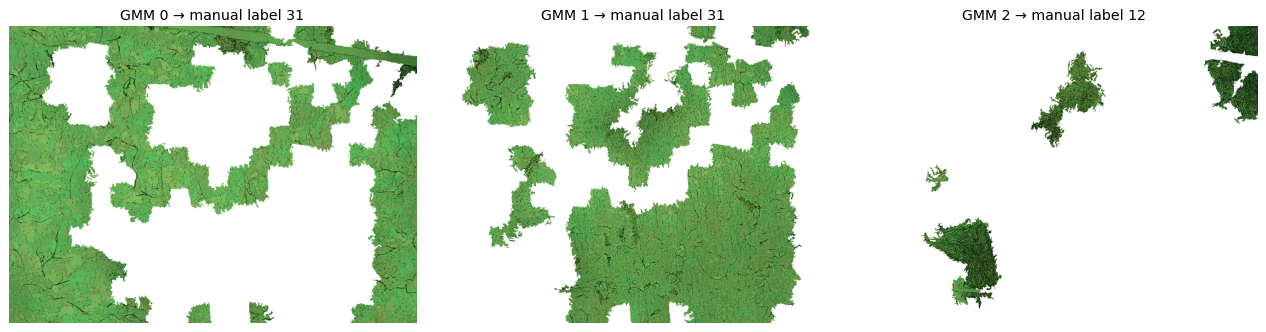

manual_label,1,3
name,,
0053_20260807_103050,17,233
20260805_125544,130,89
20260805_125625,151,86
20260806_143420,163,36
20260807_100809,85,131
20260807_102830,20,216
20260807_124648,64,156
20260807_124732,111,117


In [6]:
cluster_rows = []
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    feature_path = prepare_image(PROJECT_ROOT / row.path, directory)
    result = fit_image_gmm(feature_path, row.n_components, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
    np.savez_compressed(directory / "gmm.npz", **result)
    for cluster, manual in enumerate(json.loads(row.archive_labels)):
        cluster_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": cluster, "archive_manual_label": manual,
                             "manual_label": manual if manual in LABEL_TO_CLASS else np.nan,
                             "n_superpixels": int(np.count_nonzero(result["cluster_labels"] == cluster)), "archive_index": row.archive_index})
    print(f"{row.image_id+1}/8: {row.name}; {len(result['valid_indices'])} superpixels; labels {row.archive_labels}", flush=True)
    gc.collect()
LABEL_PATH = OUTPUT_DIR / "cluster_labels.csv"
if not LABEL_PATH.exists(): pd.DataFrame(cluster_rows).to_csv(LABEL_PATH, index=False)
display(pd.read_csv(LABEL_PATH))
first = manifest.iloc[0]
directory = OUTPUT_DIR / "rf_data" / f"image_{first.image_id:04d}"
training_image, training_segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
with np.load(directory / "features.npz") as saved: labels = saved["labels"]
with np.load(directory / "gmm.npz") as saved:
    groups = np.full(len(labels), -1, dtype=int)
    groups[saved["valid_indices"]] = saved["cluster_labels"]
fig, axes = plt.subplots(1, int(first.n_components), figsize=(5 * int(first.n_components), 4), squeeze=False)
for cluster, ax in enumerate(axes.flat):
    view = np.full_like(training_image, 255)
    mask = groups[np.searchsorted(labels, training_segments)] == cluster
    view[mask] = training_image[mask]
    manual = pd.read_csv(LABEL_PATH).query("image_id == @first.image_id and gmm_cluster == @cluster").manual_label.iloc[0]
    ax.imshow(view)
    label_text = f"manual label {int(manual)}" if pd.notna(manual) else "excluded archived class"
    ax.set_title(f"GMM {cluster} → {label_text}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_archived_labels.png", dpi=120)
plt.show()
plt.close(fig)
del training_image, training_segments, view

# Expand manual group labels and select eligible supervised rows.
manual = pd.read_csv(LABEL_PATH)
if manual.duplicated(["image_id", "gmm_cluster"]).any(): raise ValueError("Duplicate manual cluster rows.")
rows = []
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    with np.load(directory / "features.npz") as saved: features, labels = saved["features"], saved["labels"]
    with np.load(directory / "gmm.npz") as saved:
        indices, clusters, probability = saved["valid_indices"], saved["cluster_labels"], saved["max_probability"]
    annotations = manual[manual.image_id == row.image_id]
    if set(annotations.gmm_cluster) != set(range(row.n_components)) or set(annotations.name) != {row.name}:
        raise ValueError("Manual annotations do not match the selected image/GMM.")
    lookup = pd.to_numeric(annotations.set_index("gmm_cluster").manual_label, errors="raise")
    if not set(lookup.dropna()).issubset(LABEL_TO_CLASS): raise ValueError("Use raw manual labels 11, 12, 31, 32, or blanks.")
    frame = pd.DataFrame(features[indices], columns=FEATURE_NAMES)
    frame["image_id"], frame["name"], frame["image_hash"] = row.image_id, row.name, row.image_hash
    frame["superpixel_index"], frame["segment_label"] = indices, labels[indices]
    frame["gmm_cluster"], frame["gmm_probability"] = clusters, probability
    frame["source_manual_label"] = lookup.reindex(clusters).to_numpy()
    frame["manual_label"] = frame.source_manual_label.map(LABEL_TO_CLASS)
    rows.append(frame)
all_superpixels = pd.concat(rows, ignore_index=True)
all_superpixels.to_csv(OUTPUT_DIR / "superpixels.csv", index=False)
dataset = all_superpixels[all_superpixels.manual_label.notna() & (all_superpixels.gmm_probability >= GMM_PROBABILITY_CUT)].copy()
dataset["manual_label"] = dataset.manual_label.astype(int)
assert dataset.image_id.nunique() == 8 and set(dataset.manual_label) == set(CLASS_IDS)
assert dataset.groupby("image_id").manual_label.nunique().eq(2).all()
dataset.to_csv(OUTPUT_DIR / "rf_training.csv", index=False)
display(dataset.groupby(["name", "manual_label"]).size().unstack(fill_value=0))
print(f"Eligible superpixels: {len(dataset):,} / {len(all_superpixels):,}; eight mixed images, both parent groups scored in every image.")

## 7. Fit the final binary RF on all eight images

Save `rf_demo_all8.pkl` for parent groups 1 and 3. This model is not used for evaluation; the next cell creates four fresh six-image RFs. The model does not implement the full five-group classification or its subclasses.

In [7]:
final_rf = RandomForestClassifier(**RF_PARAMS).fit(dataset[FEATURE_NAMES], dataset.manual_label)
model_path = OUTPUT_DIR / "rf_demo_all8.pkl"
joblib.dump({"model": final_rf, "feature_names": FEATURE_NAMES, "feature_calculation": FEATURE_CALCULATION,
             "reference_mean": reference, "class_ids": CLASS_IDS, "manual_to_class": LABEL_TO_CLASS, "preprocessing": CONFIG,
             "training_image_hashes": manifest.image_hash.tolist(), "label_provenance": provenance,
             "purpose": "binary RF refitted on all eight images; not used for cross-validation scores"}, model_path)
print(f"Final eight-image model: {model_path}\nCross-validation outputs (created by the following cells): {CV_DIR}")
print("Edit cluster_labels.csv and rerun cells 6–9 to update labels; choose a new run directory if inputs or GMM settings change.")

Final eight-image model: /home/kmanabe2403/dune/training/output/tutorial_mixed_groups_001/rf_demo_all8.pkl
Cross-validation outputs (created by the following cells): /home/kmanabe2403/dune/training/output/tutorial_mixed_groups_001/cross_validation
Edit cluster_labels.csv and rerun cells 6–9 to update labels; choose a new run directory if inputs or GMM settings change.


## 8. Four image folds × two inference modes

Each fold holds out two complete images and fits an RF on six others. All images contain both classes. Every image is held out once and train/test image hashes are disjoint. Compare direct superpixel predictions with majority voting of those same predictions within pre-RF GMM components. Voting includes all valid superpixels; score both modes on identical eligible reference rows. Ties choose the smaller class.

In [8]:
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report
from crystal_rf import majority_vote

CV_DIR = OUTPUT_DIR / "cross_validation"
CV_DIR.mkdir(parents=True, exist_ok=True)
MODES = {"RF only": "rf_prediction", "RF + GMM vote": "rf_gmm_prediction"}
split_rows, prediction_frames, fold_rows, fold_importances = [], [], [], []
for fold, (train_position, test_position) in enumerate(KFold(n_splits=4, shuffle=True, random_state=42).split(manifest), 1):
    train_ids, test_ids = manifest.iloc[train_position].image_id, manifest.iloc[test_position].image_id
    train, test = dataset[dataset.image_id.isin(train_ids)], dataset[dataset.image_id.isin(test_ids)]
    assert train.image_id.nunique() == 6 and test.image_id.nunique() == 2
    assert set(train.image_hash).isdisjoint(test.image_hash)
    assert set(train.manual_label) == set(test.manual_label) == set(CLASS_IDS)
    model = RandomForestClassifier(**RF_PARAMS).fit(train[FEATURE_NAMES], train.manual_label)
    fold_importances.append(model.feature_importances_)
    fold_dir = CV_DIR / f"fold_{fold:02d}"
    fold_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": model, "feature_names": FEATURE_NAMES, "class_ids": CLASS_IDS, "reference_mean": reference,
                 "training_image_hashes": sorted(set(train.image_hash)), "test_image_hashes": sorted(set(test.image_hash)),
                 "fold": fold, "purpose": "six-image fit, same model for both inference modes"}, fold_dir / "evaluation_rf.pkl")
    for row in manifest.itertuples(index=False):
        split_rows.append({"fold": fold, "image_id": row.image_id, "name": row.name, "image_hash": row.image_hash,
                           "partition": "test" if row.image_id in set(test_ids) else "train"})
    image_frames = []
    for image_id in test_ids:
        directory = OUTPUT_DIR / "rf_data" / f"image_{image_id:04d}"
        with np.load(directory / "features.npz") as saved: features, labels = saved["features"], saved["labels"]
        with np.load(directory / "gmm.npz") as saved: indices, clusters = saved["valid_indices"], saved["cluster_labels"]
        direct = model.predict(pd.DataFrame(features, columns=FEATURE_NAMES))
        voted = direct.copy()
        for cluster in np.unique(clusters):
            members = indices[clusters == cluster]
            voted[members] = int(majority_vote(direct[members])[0])
        np.savez_compressed(fold_dir / f"image_{image_id:04d}_predictions.npz", labels=labels, rf_prediction=direct, rf_gmm_prediction=voted)
        scored = test[test.image_id == image_id][["image_id", "name", "superpixel_index", "segment_label", "manual_label", "gmm_probability"]].copy()
        scored["fold"] = fold
        scored["rf_prediction"], scored["rf_gmm_prediction"] = direct[scored.superpixel_index], voted[scored.superpixel_index]
        image_frames.append(scored)
    held_out = pd.concat(image_frames, ignore_index=True)
    prediction_frames.append(held_out)
    for mode, column in MODES.items():
        fold_rows.append({"fold": fold, "mode": mode, "accuracy": accuracy_score(held_out.manual_label, held_out[column]),
                          "balanced_accuracy": balanced_accuracy_score(held_out.manual_label, held_out[column]),
                          "macro_f1": f1_score(held_out.manual_label, held_out[column], labels=CLASS_IDS, average="macro"),
                          "n_train_images": 6, "n_test_images": 2, "n_train_superpixels": len(train), "n_test_superpixels": len(test)})
    print(f"Fold {fold}: train {list(train_ids)}, test {list(test_ids)}; both prediction modes evaluated.")
cv_predictions = pd.concat(prediction_frames, ignore_index=True)
cv_splits, fold_metrics = pd.DataFrame(split_rows), pd.DataFrame(fold_rows)
assert not cv_predictions.duplicated(["image_id", "superpixel_index"]).any()
assert cv_splits.query("partition == 'test'").groupby("image_id").size().eq(1).all()
assert len(cv_predictions) == len(dataset)
summary_rows, image_rows = [], []
for mode, column in MODES.items():
    fold_scores = fold_metrics[fold_metrics["mode"] == mode]
    summary_rows.append({"mode": mode, "pooled_accuracy": accuracy_score(cv_predictions.manual_label, cv_predictions[column]),
                         "pooled_balanced_accuracy": balanced_accuracy_score(cv_predictions.manual_label, cv_predictions[column]),
                         "pooled_macro_f1": f1_score(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS, average="macro"),
                         "mean_fold_accuracy": fold_scores.accuracy.mean(), "std_fold_accuracy": fold_scores.accuracy.std(),
                         "n_test_images": 8, "n_test_superpixels": len(cv_predictions)})
    for image_id, scored in cv_predictions.groupby("image_id"):
        image_rows.append({"image_id": image_id, "name": scored.name.iloc[0], "fold": scored.fold.iloc[0], "mode": mode,
                           "accuracy": accuracy_score(scored.manual_label, scored[column]), "n_superpixels": len(scored)})
cv_summary, image_metrics = pd.DataFrame(summary_rows), pd.DataFrame(image_rows)
for name, table in {"splits": cv_splits, "predictions": cv_predictions, "fold_metrics": fold_metrics,
                    "summary_metrics": cv_summary, "image_metrics": image_metrics}.items(): table.to_csv(CV_DIR / f"{name}.csv", index=False)
display(cv_splits.query("partition == 'test'")[["fold", "image_id", "name"]])
display(fold_metrics)
display(cv_summary)

Fold 1: train [0, 2, 3, 4, 6, 7], test [1, 5]; both prediction modes evaluated.
Fold 2: train [1, 2, 3, 4, 5, 6], test [0, 7]; both prediction modes evaluated.
Fold 3: train [0, 1, 3, 5, 6, 7], test [2, 4]; both prediction modes evaluated.
Fold 4: train [0, 1, 2, 4, 5, 7], test [3, 6]; both prediction modes evaluated.


,fold,image_id,name
1,1,1,20260805_125544
5,1,5,20260807_102830
8,2,0,0053_20260807_103050
15,2,7,20260807_124732
18,3,2,20260805_125625
20,3,4,20260807_100809
27,4,3,20260806_143420
30,4,6,20260807_124648


,fold,mode,accuracy,balanced_accuracy,macro_f1,n_train_images,n_test_images,n_train_superpixels,n_test_superpixels
0,1,RF only,0.971429,0.961749,0.967281,6,2,1350,455
1,1,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1350,455
2,2,RF only,0.962343,0.971808,0.953754,6,2,1327,478
3,2,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1327,478
4,3,RF only,0.931567,0.933951,0.931546,6,2,1352,453
5,3,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1352,453
6,4,RF only,0.859189,0.860407,0.858725,6,2,1386,419
7,4,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1386,419


,mode,pooled_accuracy,pooled_balanced_accuracy,pooled_macro_f1,mean_fold_accuracy,std_fold_accuracy,n_test_images,n_test_superpixels
0,RF only,0.932964,0.927776,0.930314,0.931132,0.050905,8,1805
1,RF + GMM vote,1.000000,1.000000,1.000000,1.000000,0.000000,8,1805


## 9. Compare held-out predictions and original-color groups

Show blue confusion matrices, per-fold scores and per-image prediction/correctness maps. Blue is group 1; orange is group 3. Gray means unscored because the annotation is excluded/missing or GMM confidence is below 0.70. Save a vote audit retaining the original manual-label IDs.

Finally, plot every annotated GMM group separately in original colors, first for group 1 and then group 3. Include low-confidence superpixels in these visual comparisons; white means outside that component. All plotting is inline in this cell.

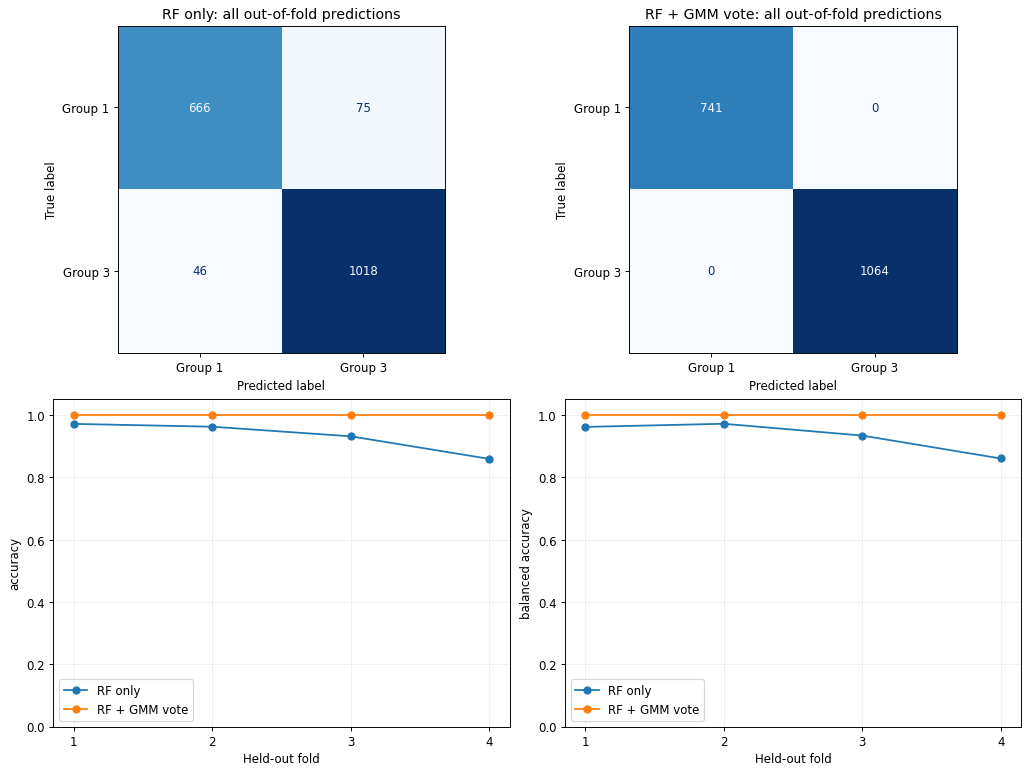

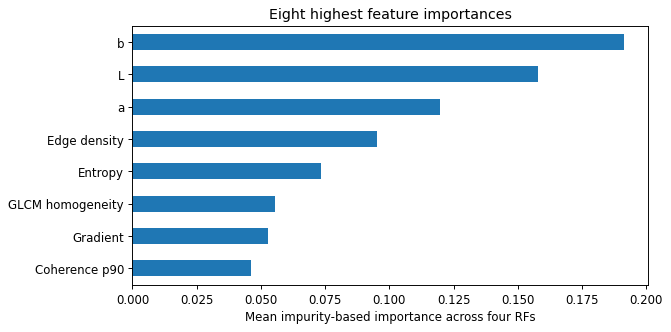

,mode,pooled_accuracy,pooled_balanced_accuracy,pooled_macro_f1,mean_fold_accuracy,std_fold_accuracy,n_test_images,n_test_superpixels
0,RF only,0.932964,0.927776,0.930314,0.931132,0.050905,8,1805
1,RF + GMM vote,1.000000,1.000000,1.000000,1.000000,0.000000,8,1805


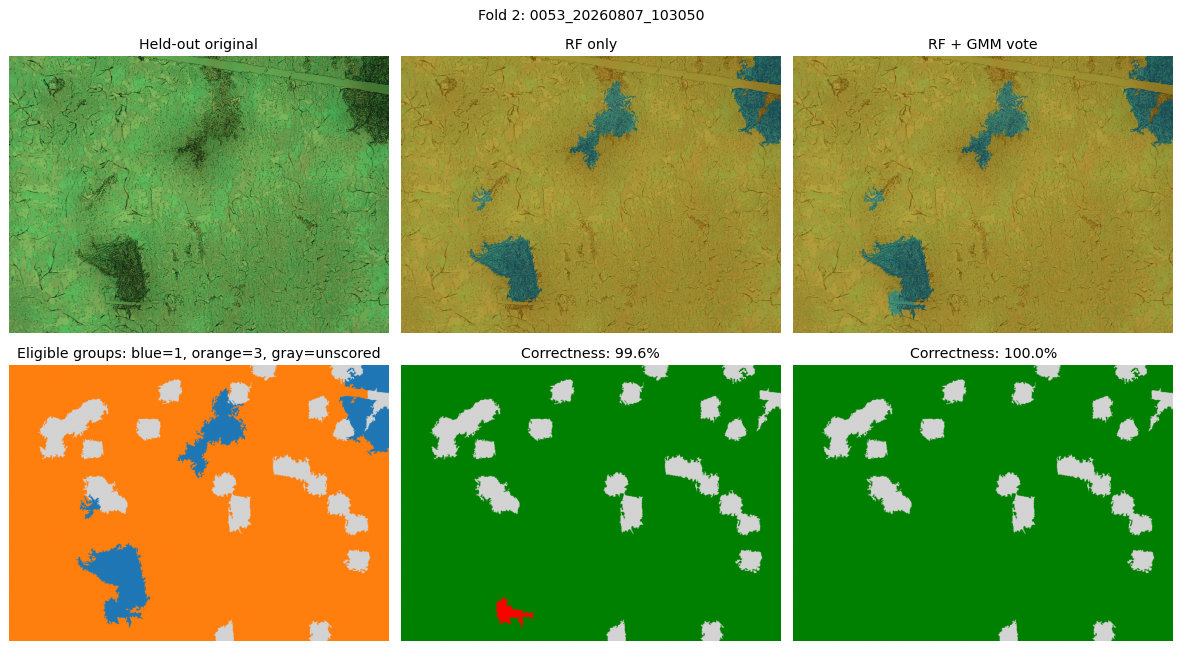

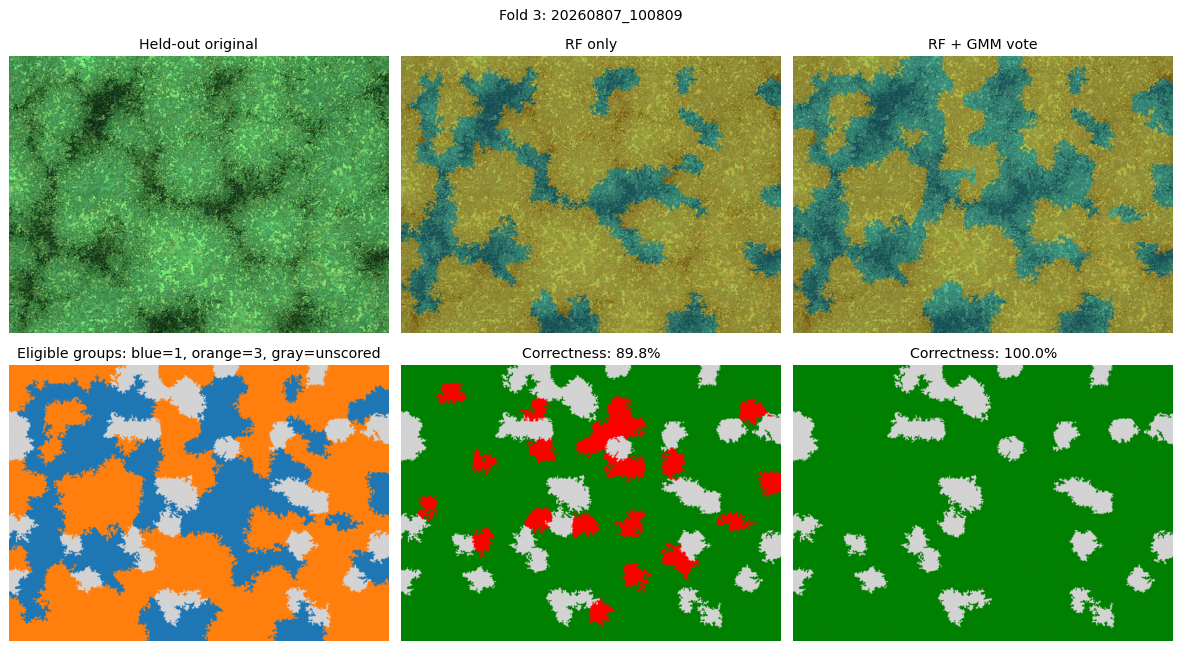

,image_id,name,fold,mode,accuracy,n_superpixels
0,0,0053_20260807_103050,2,RF only,0.996000,250
1,1,20260805_125544,1,RF only,0.977169,219
2,2,20260805_125625,3,RF only,0.962025,237
3,3,20260806_143420,4,RF only,0.824121,199
4,4,20260807_100809,3,RF only,0.898148,216
5,5,20260807_102830,1,RF only,0.966102,236
6,6,20260807_124648,4,RF only,0.890909,220
7,7,20260807_124732,2,RF only,0.925439,228
8,0,0053_20260807_103050,2,RF + GMM vote,1.000000,250
9,1,20260805_125544,1,RF + GMM vote,1.000000,219


,image_id,name,fold,gmm_cluster,source_manual_label,manual_label,n_total,n_scored,n_unscored,votes_1_all,votes_3_all,majority_label,correct_rf_scored,correct_vote_scored
0,0,0053_20260807_103050,2,0,31.0,3.0,137,128,9,0,137,3,128,128
1,0,0053_20260807_103050,2,1,31.0,3.0,121,105,16,0,121,3,105,105
2,0,0053_20260807_103050,2,2,12.0,1.0,17,17,0,16,1,1,16,17
3,1,20260805_125544,1,0,31.0,3.0,97,89,8,2,95,3,88,89
4,1,20260805_125544,1,1,11.0,1.0,143,130,13,131,12,1,126,130
5,2,20260805_125625,3,0,11.0,1.0,158,151,7,144,14,1,144,151
6,2,20260805_125625,3,1,31.0,3.0,93,86,7,2,91,3,84,86
7,3,20260806_143420,4,0,32.0,3.0,45,36,9,0,45,3,36,36
8,3,20260806_143420,4,1,11.0,1.0,165,163,2,128,37,1,128,163
9,4,20260807_100809,3,0,32.0,3.0,147,131,16,0,147,3,131,131


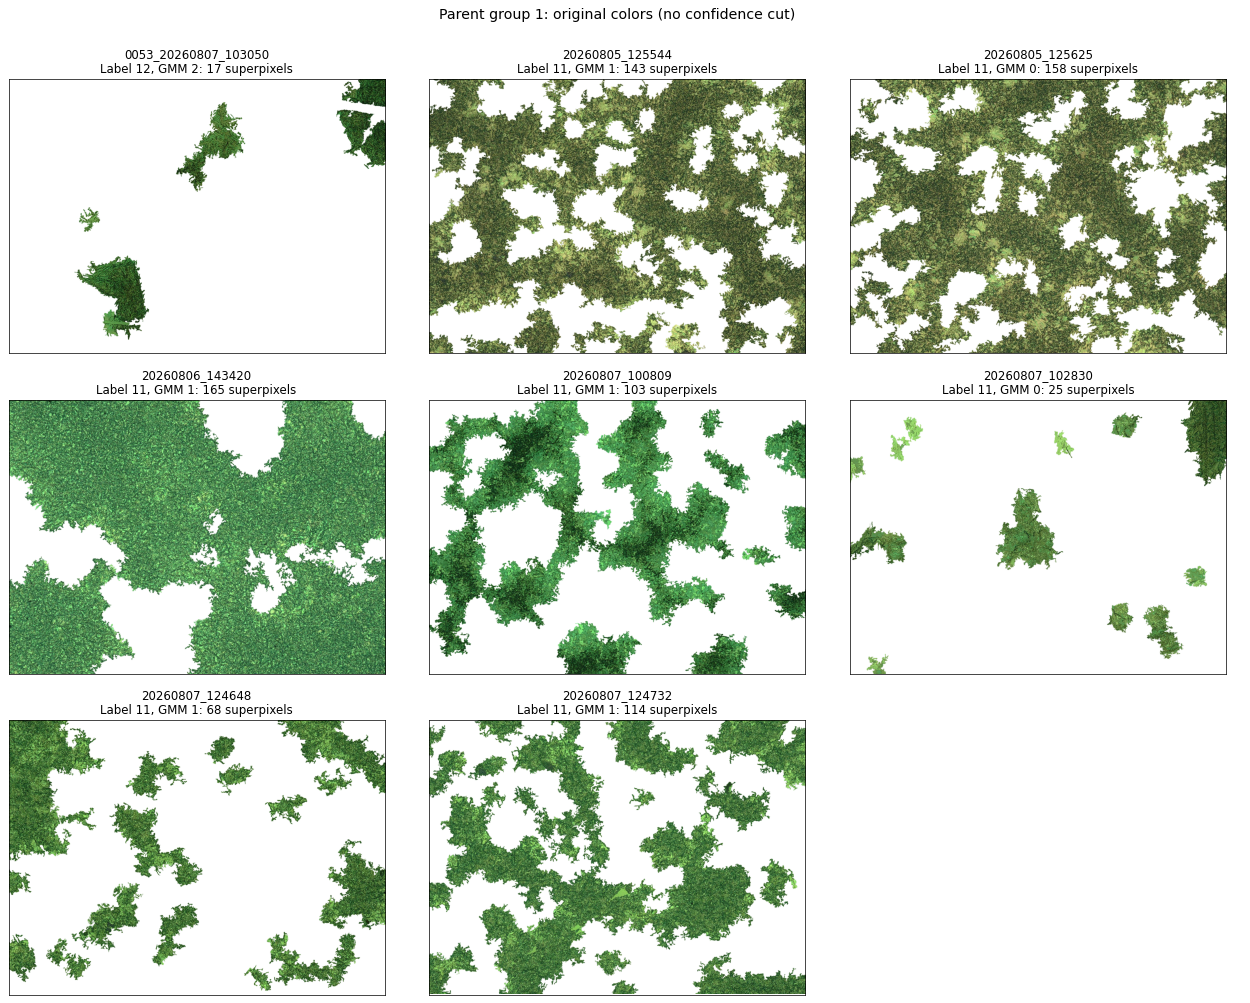

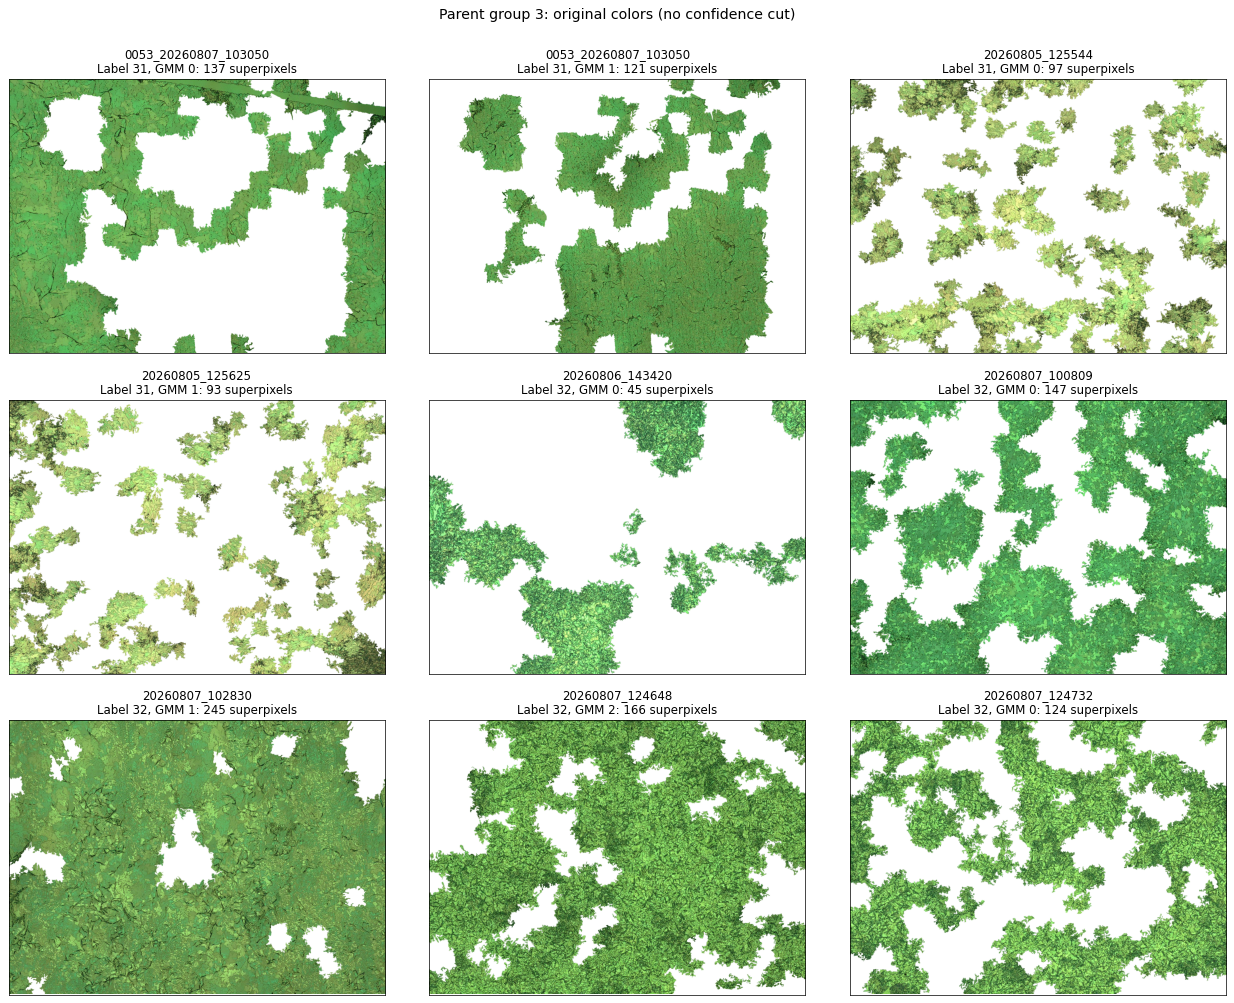

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for ax, (mode, column) in zip(axes[0], MODES.items()):
    ConfusionMatrixDisplay.from_predictions(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS,
                                           display_labels=[f"Group {c}" for c in CLASS_IDS], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{mode}: all out-of-fold predictions")
    pd.DataFrame(classification_report(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS,
                                      output_dict=True, zero_division=0)).T.to_csv(CV_DIR / f"report_{column}.csv")
for ax, metric in zip(axes[1], ["accuracy", "balanced_accuracy"]):
    for mode in MODES:
        rows = fold_metrics[fold_metrics["mode"] == mode]
        ax.plot(rows.fold, rows[metric], "o-", label=mode)
    ax.set(xlabel="Held-out fold", ylabel=metric.replace("_", " "), xticks=[1, 2, 3, 4], ylim=(0, 1.05))
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(CV_DIR / "05_cv_comparison.png", dpi=150)
plt.show()
plt.close(fig)
importance = pd.Series(np.mean(fold_importances, axis=0), index=FEATURE_NAMES).sort_values()
importance.rename("mean_importance").to_csv(CV_DIR / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(8, 4))
importance.tail(8).plot.barh(ax=ax)
ax.set(xlabel="Mean impurity-based importance across four RFs", title="Eight highest feature importances")
fig.tight_layout()
fig.savefig(CV_DIR / "feature_importance.png", dpi=120)
plt.show()
plt.close(fig)
display(cv_summary)

from matplotlib.colors import ListedColormap

figure_dir = CV_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
vote_audit_rows = []
annotations = pd.read_csv(LABEL_PATH)
for image_id in sorted(cv_predictions.image_id.unique()):
    row = manifest[manifest.image_id == image_id].iloc[0]
    scored = cv_predictions[cv_predictions.image_id == image_id]
    fold = int(scored.fold.iloc[0])
    directory = OUTPUT_DIR / "rf_data" / f"image_{image_id:04d}"
    image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
    with np.load(CV_DIR / f"fold_{fold:02d}" / f"image_{image_id:04d}_predictions.npz") as saved:
        labels, direct, voted = saved["labels"], saved["rf_prediction"], saved["rf_gmm_prediction"]
    with np.load(directory / "gmm.npz") as saved: valid, groups = saved["valid_indices"], saved["cluster_labels"]
    for cluster in np.unique(groups):
        members = valid[groups == cluster]
        eligible = scored[scored.superpixel_index.isin(members)]
        manual_value = annotations.query("image_id == @image_id and gmm_cluster == @cluster").manual_label.iloc[0]
        manual_label = int(manual_value) if pd.notna(manual_value) else np.nan
        vote_audit_rows.append({"image_id": image_id, "name": row['name'], "fold": fold, "gmm_cluster": int(cluster),
                               "source_manual_label": manual_label, "manual_label": LABEL_TO_CLASS.get(manual_label, np.nan), "n_total": len(members), "n_scored": len(eligible),
                               "n_unscored": len(members)-len(eligible), **{f"votes_{label}_all": int(np.count_nonzero(direct[members] == label)) for label in CLASS_IDS}, "majority_label": int(voted[members[0]]),
                               "correct_rf_scored": int((eligible.manual_label == eligible.rf_prediction).sum()),
                               "correct_vote_scored": int((eligible.manual_label == eligible.rf_gmm_prediction).sum())})
    indices = np.searchsorted(labels, segments)
    true_labels = np.full(len(labels), -1, dtype=int)
    true_labels[scored.superpixel_index] = [CLASS_IDS.index(int(v)) for v in scored.manual_label]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(image)
    axes[0, 0].set_title("Held-out original")
    axes[1, 0].imshow(true_labels[indices], cmap=ListedColormap(["lightgray", "tab:blue", "tab:orange"]), vmin=-1, vmax=1)
    axes[1, 0].set_title("Eligible groups: blue=1, orange=3, gray=unscored")
    for column_index, ((mode, column), full_prediction) in enumerate(zip(MODES.items(), [direct, voted]), 1):
        encoded = np.array([CLASS_IDS.index(int(v)) for v in full_prediction])
        axes[0, column_index].imshow(image)
        axes[0, column_index].imshow(encoded[indices], cmap=ListedColormap(["tab:blue", "tab:orange"]), vmin=0, vmax=1, alpha=.4)
        axes[0, column_index].set_title(mode)
        correct = np.full(len(labels), -1, dtype=int)
        correct[scored.superpixel_index] = (scored.manual_label == scored[column]).astype(int)
        axes[1, column_index].imshow(correct[indices], cmap=ListedColormap(["lightgray", "red", "green"]), vmin=-1, vmax=1)
        axes[1, column_index].set_title(f"Correctness: {(scored.manual_label == scored[column]).mean():.1%}")
    for ax in axes.flat: ax.axis("off")
    fig.suptitle(f"Fold {fold}: {row['name']}")
    fig.tight_layout()
    fig.savefig(figure_dir / f"held_out_{image_id:04d}.png", dpi=110)
    if image_id in {0, 4}: plt.show()  # Show one held-out image from each parent group.
    plt.close(fig)
    del image, segments, indices
    gc.collect()
display(image_metrics)
vote_audit = pd.DataFrame(vote_audit_rows)
vote_audit.to_csv(CV_DIR / "gmm_vote_audit.csv", index=False)
display(vote_audit)


# Compare all annotated groups in original colors; include low-confidence superpixels.
for class_id in CLASS_IDS:
    selected = annotations[annotations.manual_label.map(LABEL_TO_CLASS) == class_id].sort_values(["image_id", "gmm_cluster"])
    nrows = int(np.ceil(len(selected) / 3))
    fig, axes = plt.subplots(nrows, 3, figsize=(15, 4 * nrows), squeeze=False)
    panel_rows = []
    for ax, row in zip(axes.flat, selected.itertuples(index=False)):
        directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
        image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
        with np.load(directory / "features.npz") as saved: labels = saved["labels"]
        with np.load(directory / "gmm.npz") as saved:
            members = saved["valid_indices"][saved["cluster_labels"] == row.gmm_cluster]
        mask = np.isin(segments, labels[members])
        view = np.full_like(image, 255)
        view[mask] = image[mask]
        ax.imshow(view)
        ax.set_title(f"{row.name}\nLabel {int(row.manual_label)}, GMM {row.gmm_cluster}: {len(members)} superpixels", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values(): spine.set(color="black", linewidth=.6)
        panel_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": row.gmm_cluster,
                           "source_manual_label": row.manual_label, "parent_group": class_id, "n_superpixels": len(members)})
    for ax in axes.flat[len(selected):]: ax.axis("off")
    fig.suptitle(f"Parent group {class_id}: original colors (no confidence cut)")
    fig.tight_layout(rect=(0, 0, 1, .97), h_pad=3)
    fig.savefig(CV_DIR / f"group{class_id}_groups_comparison.png", dpi=150)
    plt.show()
    plt.close(fig)
    pd.DataFrame(panel_rows).to_csv(CV_DIR / f"group{class_id}_comparison_groups.csv", index=False)
    del image, segments, mask, view
